# Phase 4 — Multi-Seed Robustness

**Project:** Forgetting-Aware PEFT  
**Base model:** `Qwen/Qwen2.5-0.5B`  
**Target:** SAMSum  
**Methods:** LoRA, AdaLoRA, DoRA  
**Seeds:** 42, 123, 2026

## Goal
Test whether the adaptation/forgetting patterns observed in Phases 1–3 are robust to random seed.

The completed seed-42 historical run is **not overwritten**. This notebook is designed primarily to run the missing seeds 123 and 2026, with Drive-persistent checkpoints and per-evaluation caching.

Training settings remain aligned with the Proper/T4 experiment:
- 2,000 SAMSum training examples
- 2 epochs
- physical batch 2
- gradient accumulation 8
- effective batch 16
- max length 512
- learning rate 2e-4
- LoRA r=8, alpha=16, dropout=.05
- AdaLoRA init_r=12, target_r=8, tinit=50, tfinal=50, deltaT=10
- DoRA r=8, alpha=16, dropout=.05
- same target modules

**Important:** Phase 4 does not modify Phase 1, 2, or 3 artifacts.

In [1]:
!pip uninstall -y torchao
!pip -q install -U "transformers>=4.45" "peft>=0.13" "datasets>=3.0" accelerate evaluate rouge_score "pandas==2.2.3" matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.9/89.9 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.7/12.7 MB 72.1 MB/s eta 0:00:00


In [2]:
from google.colab import drive
drive.mount('/content/drive', force_remount=False)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
import gc, json, math, random, re, time
from pathlib import Path
import numpy as np, pandas as pd
import torch, torch.nn.functional as F
import matplotlib.pyplot as plt

from datasets import load_dataset
from transformers import (
    AutoTokenizer, AutoModelForCausalLM, TrainingArguments, Trainer,
    DataCollatorForSeq2Seq, TrainerCallback
)
from peft import LoraConfig, AdaLoraConfig, get_peft_model, PeftModel
import evaluate

BASE_MODEL="Qwen/Qwen2.5-0.5B"
SEEDS=[42,123,2026]
NEW_SEEDS=[123,2026]
METHODS=["lora","adalora","dora"]

TRAIN_N=2000
SAMSUM_EVAL_N=200
BOOLQ_N=500
PIQA_N=500
ARC_N=500
MMLU_N=500
MAX_LEN=512
EPOCHS=2
BATCH=2
GRAD_ACCUM=8
LR=2e-4
TARGET_MODULES=["q_proj","k_proj","v_proj","o_proj","gate_proj","up_proj","down_proj"]

ROOT=Path("/content/drive/MyDrive/forgetting-aware-peft/phase4_multiseed")
CKPT=ROOT/"checkpoints"; ADAPTERS=ROOT/"adapters"; RESULTS=ROOT/"results"
CACHE=ROOT/"eval_cache"; INDICES=ROOT/"indices"; PLOTS=ROOT/"plots"
for p in [CKPT,ADAPTERS,RESULTS,CACHE,INDICES,PLOTS]: p.mkdir(parents=True,exist_ok=True)

device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
print("Persistent root:",ROOT)

GPU: Tesla T4
Persistent root: /content/drive/MyDrive/forgetting-aware-peft/phase4_multiseed


## Data and deterministic sampling

Each seed gets its own deterministic SAMSum training sample. Evaluation subsets are fixed and saved to Drive. The same evaluation subset for a given seed is used for PRE and every PEFT method.

This phase deliberately varies the seed, so training-example sampling and stochastic optimization can vary together. The exact indices are persisted for reproducibility.

In [4]:
tok=AutoTokenizer.from_pretrained(BASE_MODEL,use_fast=True)
if tok.pad_token_id is None: tok.pad_token=tok.eos_token

samsum=load_dataset("knkarthick/samsum")
boolq=load_dataset("google/boolq")
piqa=load_dataset("lighteval/piqa")
arc=load_dataset("allenai/ai2_arc","ARC-Easy")
mmlu=load_dataset("cais/mmlu","all")
wiki=load_dataset("Salesforce/wikitext","wikitext-2-raw-v1")
rouge=evaluate.load("rouge")

In [5]:
def fixed_idx(n,k,seed,path):
    if path.exists(): return json.loads(path.read_text())
    r=random.Random(seed); x=sorted(r.sample(range(n),min(k,n)))
    path.write_text(json.dumps(x)); return x

def seed_data(seed):
    d=INDICES/f"seed_{seed}"; d.mkdir(exist_ok=True)
    tr_i=fixed_idx(len(samsum["train"]),TRAIN_N,seed,d/"samsum_train.json")
    ev_i=fixed_idx(len(samsum["test"]),SAMSUM_EVAL_N,42,d/"samsum_eval.json")
    b_i=fixed_idx(len(boolq["validation"]),BOOLQ_N,42,d/"boolq.json")
    p_i=fixed_idx(len(piqa["validation"]),PIQA_N,42,d/"piqa.json")
    a_i=fixed_idx(len(arc["validation"]),ARC_N,42,d/"arc.json")
    # Balanced MMLU fixed subset
    mp=d/"mmlu.json"
    if mp.exists(): m_i=json.loads(mp.read_text())
    else:
        ds=mmlu["validation"]; by={}
        for i,s in enumerate(ds["subject"]): by.setdefault(s,[]).append(i)
        r=random.Random(42)
        for s in by:r.shuffle(by[s])
        m_i=[]; pos={s:0 for s in by}
        while len(m_i)<min(MMLU_N,len(ds)):
            added=False
            for s in sorted(by):
                if pos[s]<len(by[s]) and len(m_i)<MMLU_N:
                    m_i.append(by[s][pos[s]]);pos[s]+=1;added=True
            if not added:break
        m_i=sorted(m_i);mp.write_text(json.dumps(m_i))
    return {
      "train":samsum["train"].select(tr_i),
      "samsum_eval":samsum["test"].select(ev_i),
      "boolq":boolq["validation"].select(b_i),
      "piqa":piqa["validation"].select(p_i),
      "arc":arc["validation"].select(a_i),
      "mmlu":mmlu["validation"].select(m_i)
    }

wiki_text="\n\n".join(x for x in wiki["test"]["text"] if x.strip())
wiki_ids=torch.tensor(tok(wiki_text,add_special_tokens=False).input_ids[:50000],dtype=torch.long)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (298938 > 131072). Running this sequence through the model will result in indexing errors


## Target-only SAMSum preprocessing
Only summary tokens contribute to training loss; prompt and padding labels are `-100`.

In [6]:
def make_train_ds(ds):
    def f(ex):
        prompt=f"Dialogue:\n{ex['dialogue']}\n\nSummary:"
        p=tok(prompt,add_special_tokens=False).input_ids
        y=tok(" "+ex["summary"]+tok.eos_token,add_special_tokens=False).input_ids
        p=p[:max(1,MAX_LEN-len(y))]
        ids=(p+y)[:MAX_LEN]
        labels=([-100]*len(p)+y)[:len(ids)]
        return {"input_ids":ids,"attention_mask":[1]*len(ids),"labels":labels}
    return ds.map(f,remove_columns=ds.column_names)

collator=DataCollatorForSeq2Seq(tok,padding=True,label_pad_token_id=-100,return_tensors="pt")

## PEFT configuration

In [7]:
def build_model(method,total_steps):
    dtype=torch.float16 if torch.cuda.is_available() else torch.float32
    base=AutoModelForCausalLM.from_pretrained(BASE_MODEL,torch_dtype=dtype,low_cpu_mem_usage=True)
    if method=="lora":
        cfg=LoraConfig(r=8,lora_alpha=16,lora_dropout=.05,target_modules=TARGET_MODULES,
                       bias="none",task_type="CAUSAL_LM")
    elif method=="dora":
        cfg=LoraConfig(r=8,lora_alpha=16,lora_dropout=.05,target_modules=TARGET_MODULES,
                       bias="none",task_type="CAUSAL_LM",use_dora=True)
    else:
        cfg=AdaLoraConfig(init_r=12,target_r=8,lora_alpha=16,lora_dropout=.05,
                          target_modules=TARGET_MODULES,bias="none",task_type="CAUSAL_LM",
                          tinit=50,tfinal=50,deltaT=10,total_step=total_steps)
    return get_peft_model(base,cfg)

class AdaUpdate(TrainerCallback):
    def __init__(self,m): self.m=m
    def on_optimizer_step(self,args,state,control,**kwargs):
        self.m.base_model.update_and_allocate(state.global_step)

## Resume-safe training

A completed adapter causes that seed/method to be skipped. Otherwise Trainer resumes from the newest Drive checkpoint. Checkpoints are written every 25 optimizer steps.

In [8]:
def latest_ckpt(folder):
    xs=[]
    if folder.exists():
        for p in folder.glob("checkpoint-*"):
            try: xs.append((int(p.name.split("-")[-1]),p))
            except: pass
    return max(xs)[1] if xs else None

def adapter_dir(seed,method): return ADAPTERS/f"seed_{seed}_{method}"
def complete(seed,method):
    p=adapter_dir(seed,method)
    return (p/"adapter_config.json").exists()

def train_one(seed,method,data):
    if complete(seed,method):
        print("SKIP completed:",seed,method); return
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)

    train_ds=make_train_ds(data["train"])
    steps=math.ceil(len(train_ds)/(BATCH*GRAD_ACCUM))*EPOCHS
    model=build_model(method,steps)
    folder=CKPT/f"seed_{seed}_{method}";folder.mkdir(exist_ok=True)

    args=TrainingArguments(
        output_dir=str(folder),num_train_epochs=EPOCHS,
        per_device_train_batch_size=BATCH,gradient_accumulation_steps=GRAD_ACCUM,
        learning_rate=LR,logging_steps=10,save_strategy="steps",save_steps=25,
        save_total_limit=3,fp16=torch.cuda.is_available(),report_to="none",
        seed=seed,data_seed=seed,remove_unused_columns=False
    )
    callbacks=[AdaUpdate(model)] if method=="adalora" else []
    trainer=Trainer(model=model,args=args,train_dataset=train_ds,
                    data_collator=collator,callbacks=callbacks)
    resume=latest_ckpt(folder)
    print("Training",seed,method,"resume:",resume)
    trainer.train(resume_from_checkpoint=str(resume) if resume else None)
    p=adapter_dir(seed,method);p.mkdir(exist_ok=True)
    model.save_pretrained(p);tok.save_pretrained(p)
    print("SAVED FINAL ADAPTER:",p)
    del trainer,model,train_ds;gc.collect()
    if torch.cuda.is_available():torch.cuda.empty_cache()

## Shared evaluation machinery

Accuracy probes use continuation likelihood; WikiText uses perplexity. SAMSum uses deterministic generation and ROUGE. Each completed evaluation is cached immediately to Drive.

In [9]:
@torch.inference_mode()
def score(model,prompt,cont):
    p=tok(prompt,add_special_tokens=False).input_ids
    c=tok(cont,add_special_tokens=False).input_ids
    p=p[-max(1,MAX_LEN-len(c)):]
    x=torch.tensor([p+c],device=device)
    logits=model(x).logits[:,len(p)-1:len(p)-1+len(c),:]
    lp=F.log_softmax(logits,dim=-1)
    y=torch.tensor([c],device=device)
    return lp.gather(-1,y.unsqueeze(-1)).squeeze(-1).mean().item()

@torch.inference_mode()
def eval_boolq(model,ds):
    ok=0
    for x in ds:
        prompt=f"Passage: {x['passage']}\nQuestion: {x['question']}\nAnswer:"
        pred=score(model,prompt," Yes")>score(model,prompt," No")
        ok+=int(pred==bool(x["answer"]))
    return ok/len(ds)

@torch.inference_mode()
def eval_piqa(model,ds):
    ok=0
    for x in ds:
        prompt=f"Goal: {x['goal']}\nSolution:"
        pred=int(score(model,prompt," "+x["sol2"])>score(model,prompt," "+x["sol1"]))
        ok+=int(pred==int(x["label"]))
    return ok/len(ds)

@torch.inference_mode()
def eval_arc(model,ds):
    ok=0
    for x in ds:
        labs=list(x["choices"]["label"]); texts=list(x["choices"]["text"]);gold=str(x["answerKey"])
        prompt="Question: "+x["question"]+"\nChoices:\n"+"\n".join(f"{a}. {b}" for a,b in zip(labs,texts))+"\nAnswer:"
        pred=labs[int(np.argmax([score(model,prompt," "+a) for a in labs]))]
        ok+=int(pred==gold)
    return ok/len(ds)

@torch.inference_mode()
def eval_mmlu(model,ds):
    labs=["A","B","C","D"];ok=0
    for x in ds:
        prompt=f"Subject: {x['subject'].replace('_',' ')}\nQuestion: {x['question']}\nChoices:\n"+               "\n".join(f"{labs[i]}. {c}" for i,c in enumerate(x["choices"]))+"\nAnswer:"
        pred=int(np.argmax([score(model,prompt," "+a) for a in labs]))
        ok+=int(pred==int(x["answer"]))
    return ok/len(ds)

@torch.inference_mode()
def eval_wiki(model):
    nll=0.;n=0
    for st in range(0,len(wiki_ids)-1,512):
        b=wiki_ids[st:st+512]
        if len(b)<2:continue
        x=b.unsqueeze(0).to(device);logits=model(x).logits[:,:-1,:];y=x[:,1:]
        nll+=F.cross_entropy(logits.reshape(-1,logits.size(-1)),y.reshape(-1),reduction="sum").item()
        n+=y.numel()
    return math.exp(nll/n)

@torch.inference_mode()
def eval_samsum(model,ds):
    preds=[];refs=[]
    for x in ds:
        prompt=f"Dialogue:\n{x['dialogue']}\n\nSummary:"
        enc=tok(prompt,return_tensors="pt",truncation=True,max_length=MAX_LEN).to(device)
        out=model.generate(**enc,max_new_tokens=96,do_sample=False,pad_token_id=tok.eos_token_id)
        txt=tok.decode(out[0][enc["input_ids"].shape[1]:],skip_special_tokens=True).strip()
        preds.append(txt);refs.append(x["summary"])
    r=rouge.compute(predictions=preds,references=refs,use_stemmer=True)
    return {"rouge1":r["rouge1"],"rouge2":r["rouge2"],"rougeL":r["rougeL"]}

In [10]:
def cachefile(seed,label,probe):return CACHE/f"seed_{seed}__{label}__{probe}.json"
def cached(seed,label,probe):
    p=cachefile(seed,label,probe)
    return json.loads(p.read_text()) if p.exists() else None
def saveval(seed,label,probe,val):
    p=cachefile(seed,label,probe);p.write_text(json.dumps(val,indent=2));print("SAVED",p);return val

def evaluate_all(seed,label,model,data):
    out={}
    funcs={
      "boolq":lambda:eval_boolq(model,data["boolq"]),
      "piqa":lambda:eval_piqa(model,data["piqa"]),
      "arc":lambda:eval_arc(model,data["arc"]),
      "mmlu":lambda:eval_mmlu(model,data["mmlu"]),
      "wikitext_ppl":lambda:eval_wiki(model),
      "samsum":lambda:eval_samsum(model,data["samsum_eval"])
    }
    for probe,f in funcs.items():
        v=cached(seed,label,probe)
        if v is None:v=saveval(seed,label,probe,f())
        else:print("CACHE HIT",seed,label,probe)
        out[probe]=v
    return out

def load_base():
    dt=torch.float16 if torch.cuda.is_available() else torch.float32
    m=AutoModelForCausalLM.from_pretrained(BASE_MODEL,torch_dtype=dt,low_cpu_mem_usage=True)
    return m.to(device).eval()

# Run missing seeds 123 and 2026

For each seed:
1. evaluate/cache the untouched PRE model;
2. train/resume each PEFT method;
3. evaluate/cache POST immediately;
4. release GPU memory before the next method.

This is intentionally sequential for T4 reliability.

In [11]:
for seed in NEW_SEEDS:
    print("\n===== SEED",seed,"=====")
    data=seed_data(seed)

    # PRE once per seed
    needed=any(cached(seed,"base",p) is None for p in ["boolq","piqa","arc","mmlu","wikitext_ppl","samsum"])
    if needed:
        m=load_base(); evaluate_all(seed,"base",m,data);del m;gc.collect();torch.cuda.empty_cache()
    else: print("Base evaluation already complete.")

    for method in METHODS:
        train_one(seed,method,data)
        needed=any(cached(seed,method,p) is None for p in ["boolq","piqa","arc","mmlu","wikitext_ppl","samsum"])
        if needed:
            base=load_base();m=PeftModel.from_pretrained(base,str(adapter_dir(seed,method))).to(device).eval()
            evaluate_all(seed,method,m,data)
            del m,base;gc.collect();torch.cuda.empty_cache()
        else: print("Evaluation already complete:",seed,method)


===== SEED 123 =====


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

...

Training 2026 dora resume: None


Step,Training Loss
10,1.621522
20,1.568510
30,1.548392
40,1.589504
50,1.534939
60,1.591565
70,1.538665
80,1.506710
90,1.556705
100,1.473566


SAVED FINAL ADAPTER: /content/drive/MyDrive/forgetting-aware-peft/phase4_multiseed/adapters/seed_2026_dora


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

SAVED /content/drive/MyDrive/forgetting-aware-peft/phase4_multiseed/eval_cache/seed_2026__dora__boolq.json
SAVED /content/drive/MyDrive/forgetting-aware-peft/phase4_multiseed/eval_cache/seed_2026__dora__piqa.json
SAVED /content/drive/MyDrive/forgetting-aware-peft/phase4_multiseed/eval_cache/seed_2026__dora__arc.json
SAVED /content/drive/MyDrive/forgetting-aware-peft/phase4_multiseed/eval_cache/seed_2026__dora__mmlu.json
SAVED /content/drive/MyDrive/forgetting-aware-peft/phase4_multiseed/eval_cache/seed_2026__dora__wikitext_ppl.json
SAVED /content/drive/MyDrive/forgetting-aware-peft/phase4_multiseed/eval_cache/seed_2026__dora__samsum.json


## Seed-42 historical values

Seed 42 is preserved from the completed Phases 1–3 rather than retrained here. Entered below are the completed historical summary values already established by those phases. The aggregation marks their provenance explicitly.

In [12]:
seed42={
 "lora":{"samsum_gain":0.098770,"boolq_gap":-0.008,"piqa_gap":-0.016,"arc_gap":0.002,"mmlu_gap":-0.006,"wiki_gap":0.827},
 "adalora":{"samsum_gain":0.0676,"boolq_gap":0.006,"piqa_gap":0.000,"arc_gap":0.004,"mmlu_gap":-0.004,"wiki_gap":-0.005},
 "dora":{"samsum_gain":0.1109,"boolq_gap":-0.010,"piqa_gap":-0.016,"arc_gap":0.002,"mmlu_gap":-0.010,"wiki_gap":0.961}
}

## Aggregate all three seeds

Positive gap always means degradation:
- accuracy: PRE − POST
- WikiText perplexity: POST − PRE
- SAMSum gain: POST ROUGE-L − PRE ROUGE-L

In [13]:
rows=[]
for method in METHODS:
    rows.append({"seed":42,"method":method,"provenance":"historical_phases_1_3",**seed42[method]})

for seed in NEW_SEEDS:
    basevals={p:cached(seed,"base",p) for p in ["boolq","piqa","arc","mmlu","wikitext_ppl","samsum"]}
    for method in METHODS:
        v={p:cached(seed,method,p) for p in ["boolq","piqa","arc","mmlu","wikitext_ppl","samsum"]}
        rows.append({
          "seed":seed,"method":method,"provenance":"phase4",
          "samsum_gain":v["samsum"]["rougeL"]-basevals["samsum"]["rougeL"],
          "boolq_gap":basevals["boolq"]-v["boolq"],
          "piqa_gap":basevals["piqa"]-v["piqa"],
          "arc_gap":basevals["arc"]-v["arc"],
          "mmlu_gap":basevals["mmlu"]-v["mmlu"],
          "wiki_gap":v["wikitext_ppl"]-basevals["wikitext_ppl"]
        })

raw=pd.DataFrame(rows)
raw.to_csv(RESULTS/"phase4_all_seeds_raw.csv",index=False)
raw

,seed,method,provenance,samsum_gain,boolq_gap,piqa_gap,arc_gap,mmlu_gap,wiki_gap
0,42,lora,historical_phases_1_3,0.098770,-0.008,-0.016,0.002,-0.006,0.827000
1,42,adalora,historical_phases_1_3,0.067600,0.006,0.000,0.004,-0.004,-0.005000
2,42,dora,historical_phases_1_3,0.110900,-0.010,-0.016,0.002,-0.010,0.961000
3,123,lora,phase4,0.097577,-0.034,-0.020,0.006,-0.002,0.937861
4,123,adalora,phase4,0.049176,-0.004,-0.004,0.002,0.000,-0.002068
5,123,dora,phase4,0.097309,-0.030,-0.020,0.006,-0.002,1.018196
6,2026,lora,phase4,0.099880,-0.022,-0.014,0.024,0.006,0.873994
7,2026,adalora,phase4,0.045899,-0.010,0.004,-0.006,0.006,-0.004998
8,2026,dora,phase4,0.102607,-0.018,-0.008,0.026,0.012,0.935680


In [14]:
metrics=["samsum_gain","boolq_gap","piqa_gap","arc_gap","mmlu_gap","wiki_gap"]
summary=raw.groupby("method")[metrics].agg(["mean","std"])
summary.to_csv(RESULTS/"phase4_mean_std.csv")
summary

samsum_gain           boolq_gap            piqa_gap            \
               mean       std      mean       std      mean       std   
method                                                                  
adalora    0.054225  0.011698 -0.002667  0.008083  0.000000  0.004000   
dora       0.103605  0.006850 -0.019333  0.010066 -0.014667  0.006110   
lora       0.098742  0.001152 -0.021333  0.013013 -0.016667  0.003055   

              arc_gap                mmlu_gap            wiki_gap            
                 mean       std          mean       std      mean       std  
method                                                                       
adalora -1.156482e-18  0.005292  6.666667e-04  0.005033 -0.004022  0.001692  
dora     1.133333e-02  0.012858  2.891206e-18  0.011136  0.971625  0.042271  
lora     1.066667e-02  0.011719 -6.666667e-04  0.006110  0.879618  0.055644

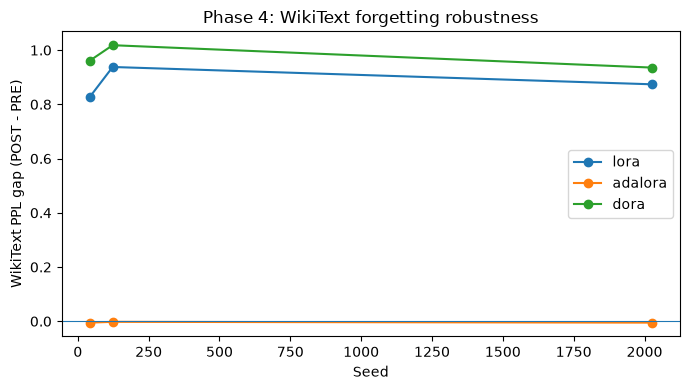

In [15]:
# Paper-oriented plot: WikiText PPL gap across seeds
fig,ax=plt.subplots(figsize=(7,4))
for method in METHODS:
    d=raw[raw.method==method]
    ax.plot(d.seed,d.wiki_gap,marker="o",label=method)
ax.axhline(0,linewidth=.8)
ax.set_xlabel("Seed");ax.set_ylabel("WikiText PPL gap (POST - PRE)")
ax.set_title("Phase 4: WikiText forgetting robustness")
ax.legend();plt.tight_layout()
plt.savefig(PLOTS/"wiki_gap_across_seeds.png",dpi=200);plt.show()

In [2]:
from google.colab import drive
drive.mount('/content/drive', force_remount=False)

Mounted at /content/drive


In [4]:
from pathlib import Path
import json

# Re-create Phase 4 configuration after Colab runtime reset
BASE_MODEL = "Qwen/Qwen2.5-0.5B"

SEEDS = [42, 123, 2026]
METHODS = ["lora", "adalora", "dora"]

TRAIN_N = 2000
EPOCHS = 2

BATCH = 2
GRAD_ACCUM = 8
LR = 2e-4
MAX_LEN = 512

ROOT = Path(
    "/content/drive/MyDrive/forgetting-aware-peft/phase4_multiseed"
)

RESULTS = ROOT / "results"
ADAPTERS = ROOT / "adapters"
CKPT = ROOT / "checkpoints"
CACHE = ROOT / "eval_cache"

RESULTS.mkdir(parents=True, exist_ok=True)

print("Phase 4 configuration restored")
print("Root exists:", ROOT.exists())
print("Results:", RESULTS)
print("Adapters:", ADAPTERS)
print("Cache:", CACHE)

Phase 4 configuration restored
Root exists: True
Results: /content/drive/MyDrive/forgetting-aware-peft/phase4_multiseed/results
Adapters: /content/drive/MyDrive/forgetting-aware-peft/phase4_multiseed/adapters
Cache: /content/drive/MyDrive/forgetting-aware-peft/phase4_multiseed/eval_cache


In [5]:
# ============================================================
# PHASE 4 — RECOVERY + FINAL RESULTS
# CPU ONLY — NO TRAINING / NO GPU REQUIRED
# ============================================================

from pathlib import Path
import json
import math
import numpy as np
import pandas as pd

ROOT = Path(
    "/content/drive/MyDrive/forgetting-aware-peft/phase4_multiseed"
)

CACHE = ROOT / "eval_cache"
RESULTS = ROOT / "results"
RESULTS.mkdir(parents=True, exist_ok=True)

SEEDS = [123, 2026]
METHODS = ["lora", "adalora", "dora"]

# ------------------------------------------------------------
# Convert numpy/pandas objects into normal Python objects
# ------------------------------------------------------------

def clean_json(obj):
    if isinstance(obj, dict):
        return {str(k): clean_json(v) for k, v in obj.items()}

    if isinstance(obj, (list, tuple)):
        return [clean_json(v) for v in obj]

    if isinstance(obj, np.ndarray):
        return obj.tolist()

    if isinstance(obj, np.integer):
        return int(obj)

    if isinstance(obj, np.floating):
        return float(obj)

    if isinstance(obj, np.bool_):
        return bool(obj)

    if pd.isna(obj):
        return None

    return obj


# ------------------------------------------------------------
# Read one cached JSON
# ------------------------------------------------------------

def read_cache(seed, model_name, probe):

    path = CACHE / f"seed_{seed}__{model_name}__{probe}.json"

    if not path.exists():
        return None

    with open(path, "r") as f:
        return json.load(f)


# ------------------------------------------------------------
# Extract scalar metric
# Most BoolQ / PIQA / ARC / MMLU cache files are scalar JSON.
# ------------------------------------------------------------

def scalar_value(x):

    if x is None:
        return None

    if isinstance(x, (int, float)):
        return float(x)

    if isinstance(x, dict):

        # common possible names
        for key in [
            "accuracy",
            "acc",
            "score",
            "value",
            "perplexity",
            "ppl"
        ]:
            if key in x and isinstance(x[key], (int, float)):
                return float(x[key])

    return None


# ------------------------------------------------------------
# Extract SAMSum ROUGE values
# ------------------------------------------------------------

def samsum_values(x):

    if x is None:
        return {}

    if not isinstance(x, dict):
        return {}

    aliases = {
        "rouge1": ["rouge1", "r1", "ROUGE-1"],
        "rouge2": ["rouge2", "r2", "ROUGE-2"],
        "rougeL": ["rougeL", "rougel", "rl", "ROUGE-L"]
    }

    out = {}

    for canonical, keys in aliases.items():

        for key in keys:

            if key in x and isinstance(x[key], (int, float)):
                out[canonical] = float(x[key])
                break

    return out


# ------------------------------------------------------------
# Verify cache inventory
# ------------------------------------------------------------

expected_probes = [
    "boolq",
    "piqa",
    "arc",
    "mmlu",
    "wikitext_ppl",
    "samsum"
]

print("Checking Phase 4 cache...\n")

missing = []

for seed in SEEDS:

    for model_name in ["base"] + METHODS:

        for probe in expected_probes:

            path = CACHE / f"seed_{seed}__{model_name}__{probe}.json"

            if not path.exists():
                missing.append(path.name)

print("Expected files:", len(SEEDS) * 4 * len(expected_probes))
print("Missing files:", len(missing))

if missing:
    print("\nMissing:")
    for x in missing:
        print(" -", x)
else:
    print("All Phase 4 seed 123/2026 evaluation files found ✅")


# ------------------------------------------------------------
# Construct per-seed results
# ------------------------------------------------------------

rows = []

for seed in SEEDS:

    # PRE = base model
    base_boolq = scalar_value(read_cache(seed, "base", "boolq"))
    base_piqa  = scalar_value(read_cache(seed, "base", "piqa"))
    base_arc   = scalar_value(read_cache(seed, "base", "arc"))
    base_mmlu  = scalar_value(read_cache(seed, "base", "mmlu"))
    base_ppl   = scalar_value(read_cache(seed, "base", "wikitext_ppl"))

    base_samsum = samsum_values(
        read_cache(seed, "base", "samsum")
    )

    for method in METHODS:

        post_boolq = scalar_value(read_cache(seed, method, "boolq"))
        post_piqa  = scalar_value(read_cache(seed, method, "piqa"))
        post_arc   = scalar_value(read_cache(seed, method, "arc"))
        post_mmlu  = scalar_value(read_cache(seed, method, "mmlu"))
        post_ppl   = scalar_value(read_cache(seed, method, "wikitext_ppl"))

        post_samsum = samsum_values(
            read_cache(seed, method, "samsum")
        )

        row = {
            "seed": seed,
            "method": method,

            # ----------------------------
            # BoolQ
            # ----------------------------
            "boolq_pre": base_boolq,
            "boolq_post": post_boolq,
            "boolq_forgetting":
                None if base_boolq is None or post_boolq is None
                else base_boolq - post_boolq,

            # ----------------------------
            # PIQA
            # ----------------------------
            "piqa_pre": base_piqa,
            "piqa_post": post_piqa,
            "piqa_forgetting":
                None if base_piqa is None or post_piqa is None
                else base_piqa - post_piqa,

            # ----------------------------
            # ARC
            # ----------------------------
            "arc_pre": base_arc,
            "arc_post": post_arc,
            "arc_forgetting":
                None if base_arc is None or post_arc is None
                else base_arc - post_arc,

            # ----------------------------
            # MMLU
            # ----------------------------
            "mmlu_pre": base_mmlu,
            "mmlu_post": post_mmlu,
            "mmlu_forgetting":
                None if base_mmlu is None or post_mmlu is None
                else base_mmlu - post_mmlu,

            # ----------------------------
            # WikiText-2
            # Here increase in perplexity = degradation
            # ----------------------------
            "wikitext_pre_ppl": base_ppl,
            "wikitext_post_ppl": post_ppl,
            "wikitext_ppl_increase":
                None if base_ppl is None or post_ppl is None
                else post_ppl - base_ppl,

            # ----------------------------
            # SAMSum
            # POST - PRE = target-task gain
            # ----------------------------
            "samsum_r1_pre": base_samsum.get("rouge1"),
            "samsum_r1_post": post_samsum.get("rouge1"),

            "samsum_r2_pre": base_samsum.get("rouge2"),
            "samsum_r2_post": post_samsum.get("rouge2"),

            "samsum_rl_pre": base_samsum.get("rougeL"),
            "samsum_rl_post": post_samsum.get("rougeL"),
        }

        for metric in ["r1", "r2", "rl"]:

            pre = row[f"samsum_{metric}_pre"]
            post = row[f"samsum_{metric}_post"]

            row[f"samsum_{metric}_gain"] = (
                None
                if pre is None or post is None
                else post - pre
            )

        rows.append(row)


df = pd.DataFrame(rows)

# ------------------------------------------------------------
# Save per-seed results
# ------------------------------------------------------------

per_seed_path = RESULTS / "phase4_seed123_2026_results.csv"

df.to_csv(
    per_seed_path,
    index=False
)

print("\nPer-seed table:")
display(df)

print("\nSaved:", per_seed_path)


# ------------------------------------------------------------
# Mean + standard deviation for seeds 123 and 2026
# ------------------------------------------------------------

numeric_cols = [
    c for c in df.columns
    if c not in ["seed", "method"]
]

summary_rows = []

for method in METHODS:

    part = df[df["method"] == method]

    for metric in numeric_cols:

        values = pd.to_numeric(
            part[metric],
            errors="coerce"
        ).dropna()

        if len(values) == 0:
            continue

        summary_rows.append({
            "method": method,
            "metric": metric,
            "n": len(values),
            "mean": float(values.mean()),
            "std": (
                float(values.std(ddof=1))
                if len(values) > 1
                else None
            )
        })


summary = pd.DataFrame(summary_rows)

summary_path = RESULTS / "phase4_seed123_2026_summary.csv"

summary.to_csv(
    summary_path,
    index=False
)

print("\nMean / SD table:")
display(summary)

print("\nSaved:", summary_path)


# ------------------------------------------------------------
# Save recovery JSON
# ------------------------------------------------------------

record = {
    "phase": "phase4_multiseed_robustness",
    "base_model": "Qwen/Qwen2.5-0.5B",
    "target": "SAMSum",

    "new_seeds_completed": [123, 2026],

    "methods": METHODS,

    "training": {
        "train_n": 2000,
        "epochs": 2,
        "batch": 2,
        "grad_accum": 8,
        "effective_batch": 16,
        "lr": 2e-4,
        "max_len": 512
    },

    "per_seed_results": clean_json(
        df.to_dict(orient="records")
    ),

    "summary_seed123_2026": clean_json(
        summary.to_dict(orient="records")
    ),

    "notes": [
        "Seeds 123 and 2026 were trained in Phase 4.",
        "Seed 42 is the historical run from Phases 1-3 and is not retrained here.",
        "Positive BoolQ/PIQA/ARC/MMLU forgetting gaps indicate degradation.",
        "Positive WikiText perplexity increase indicates degradation.",
        "Positive SAMSum ROUGE gain indicates target-task improvement.",
        "Three-seed aggregation should combine these results with the historical seed-42 results."
    ]
}

json_path = RESULTS / "phase4_recovered_results.json"

with open(json_path, "w") as f:
    json.dump(
        clean_json(record),
        f,
        indent=2
    )


print("\n======================================")
print("PHASE 4 RECOVERY COMPLETE ✅")
print("======================================")

print("\nJSON:")
print(json_path)

print("\nPer-seed CSV:")
print(per_seed_path)

print("\nSummary CSV:")
print(summary_path)

print("\nNo training was performed.")

Checking Phase 4 cache...

Expected files: 48
Missing files: 0
All Phase 4 seed 123/2026 evaluation files found ✅

Per-seed table:


,seed,method,boolq_pre,boolq_post,boolq_forgetting,piqa_pre,piqa_post,piqa_forgetting,arc_pre,arc_post,...,wikitext_ppl_increase,samsum_r1_pre,samsum_r1_post,samsum_r2_pre,samsum_r2_post,samsum_rl_pre,samsum_rl_post,samsum_r1_gain,samsum_r2_gain,samsum_rl_gain
0,123,lora,0.62,0.654,-0.034,0.674,0.694,-0.020,0.718,0.712,...,0.937861,0.377699,0.485701,0.149415,0.235674,0.311376,0.408953,0.108001,0.086259,0.097577
1,123,adalora,0.62,0.624,-0.004,0.674,0.678,-0.004,0.718,0.716,...,-0.002068,0.377699,0.433916,0.149415,0.190743,0.311376,0.360553,0.056217,0.041328,0.049176
2,123,dora,0.62,0.650,-0.030,0.674,0.694,-0.020,0.718,0.712,...,1.018196,0.377699,0.484744,0.149415,0.235481,0.311376,0.408685,0.107045,0.086065,0.097309
3,2026,lora,0.62,0.642,-0.022,0.674,0.688,-0.014,0.718,0.694,...,0.873994,0.377699,0.491494,0.149415,0.240933,0.311376,0.411257,0.113795,0.091518,0.099880
4,2026,adalora,0.62,0.630,-0.010,0.674,0.670,0.004,0.718,0.724,...,-0.004998,0.377699,0.431801,0.149415,0.187162,0.311376,0.357276,0.054102,0.037746,0.045899
5,2026,dora,0.62,0.638,-0.018,0.674,0.682,-0.008,0.718,0.692,...,0.935680,0.377699,0.494235,0.149415,0.243409,0.311376,0.413983,0.116536,0.093994,0.102607



Saved: /content/drive/MyDrive/forgetting-aware-peft/phase4_multiseed/results/phase4_seed123_2026_results.csv

Mean / SD table:


,method,metric,n,mean,std
0,lora,boolq_pre,2,0.620000,0.000000
1,lora,boolq_post,2,0.648000,0.008485
2,lora,boolq_forgetting,2,-0.028000,0.008485
3,lora,piqa_pre,2,0.674000,0.000000
4,lora,piqa_post,2,0.691000,0.004243
...,...,...,...,...,...
67,dora,samsum_rl_pre,2,0.311376,0.000000
68,dora,samsum_rl_post,2,0.411334,0.003746
69,dora,samsum_r1_gain,2,0.111790,0.006711
70,dora,samsum_r2_gain,2,0.090030,0.005606



Saved: /content/drive/MyDrive/forgetting-aware-peft/phase4_multiseed/results/phase4_seed123_2026_summary.csv

PHASE 4 RECOVERY COMPLETE ✅

JSON:
/content/drive/MyDrive/forgetting-aware-peft/phase4_multiseed/results/phase4_recovered_results.json

Per-seed CSV:
/content/drive/MyDrive/forgetting-aware-peft/phase4_multiseed/results/phase4_seed123_2026_results.csv

Summary CSV:
/content/drive/MyDrive/forgetting-aware-peft/phase4_multiseed/results/phase4_seed123_2026_summary.csv

No training was performed.


In [6]:
from pathlib import Path
import pandas as pd
import json
import numpy as np

# ============================================================
# FINAL 3-SEED AGGREGATION
# Seed 42   -> historical Phase 1/2/3
# Seed 123  -> Phase 4
# Seed 2026 -> Phase 4
# NO TRAINING / NO GPU
# ============================================================

DRIVE_ROOT = Path("/content/drive/MyDrive/forgetting-aware-peft")

P2 = DRIVE_ROOT / "phase2_resume" / "results"
P3 = DRIVE_ROOT / "phase3_multicapability" / "results"
P4 = DRIVE_ROOT / "phase4_multiseed" / "results"

# ---------- verify files ----------
required = [
    P2 / "results.csv",
    P3 / "phase3_multicapability_results.csv",
    P4 / "phase4_seed123_2026_results.csv",
]

print("Checking required files...\n")

for f in required:
    print(f.name, "->", "FOUND ✅" if f.exists() else "MISSING ❌")

assert all(f.exists() for f in required), "One or more required files are missing."

# ============================================================
# LOAD PHASE 4 — seeds 123 + 2026
# ============================================================

phase4 = pd.read_csv(P4 / "phase4_seed123_2026_results.csv")

print("\nPhase 4 rows:", len(phase4))
print(phase4[["seed", "method"]])

# ============================================================
# LOAD HISTORICAL RESULTS
# ============================================================

phase2 = pd.read_csv(P2 / "results.csv")
phase3 = pd.read_csv(P3 / "phase3_multicapability_results.csv")

print("\nPhase 2 columns:")
print(phase2.columns.tolist())

print("\nPhase 3 columns:")
print(phase3.columns.tolist())

print("\nPhase 4 columns:")
print(phase4.columns.tolist())

Checking required files...

results.csv -> FOUND ✅
phase3_multicapability_results.csv -> FOUND ✅
phase4_seed123_2026_results.csv -> FOUND ✅

Phase 4 rows: 6
   seed   method
0   123     lora
1   123  adalora
2   123     dora
3  2026     lora
4  2026  adalora
5  2026     dora

Phase 2 columns:
['experiment_id', 'timestamp', 'phase', 'comparison_view', 'base_model', 'peft_method', 'seed', 'train_dataset', 'train_samples', 'boolq_samples', 'piqa_samples', 'samsum_eval_samples', 'epochs', 'per_device_train_batch_size', 'gradient_accumulation_steps', 'effective_batch_size', 'learning_rate', 'samsum_max_length', 'optimization_steps', 'lora_rank', 'lora_alpha', 'lora_dropout', 'target_modules', 'use_dora', 'adalora_init_r', 'adalora_target_r', 'adalora_tinit', 'adalora_tfinal', 'adalora_deltaT', 'adalora_rank_pattern', 'total_parameters', 'trainable_parameters', 'trainable_percentage', 'training_time_seconds', 'peak_gpu_memory_mb', 'samsum_pre_rouge1', 'samsum_pre_rouge2', 'samsum_pre_rougeL'

In [7]:
print("\n===== PHASE 2 =====")
for c in phase2.columns:
    print(c)

print("\n===== PHASE 3 =====")
for c in phase3.columns:
    print(c)

print("\n===== PHASE 4 =====")
for c in phase4.columns:
    print(c)


===== PHASE 2 =====
experiment_id
timestamp
phase
comparison_view
base_model
peft_method
seed
train_dataset
train_samples
boolq_samples
piqa_samples
samsum_eval_samples
epochs
per_device_train_batch_size
gradient_accumulation_steps
effective_batch_size
learning_rate
samsum_max_length
optimization_steps
lora_rank
lora_alpha
lora_dropout
target_modules
use_dora
adalora_init_r
adalora_target_r
adalora_tinit
adalora_tfinal
adalora_deltaT
adalora_rank_pattern
total_parameters
trainable_parameters
trainable_percentage
training_time_seconds
peak_gpu_memory_mb
samsum_pre_rouge1
samsum_pre_rouge2
samsum_pre_rougeL
samsum_post_rouge1
samsum_post_rouge2
samsum_post_rougeL
samsum_rouge1_gain
samsum_rouge2_gain
samsum_rougeL_gain
boolq_pre_accuracy
boolq_post_accuracy
boolq_forgetting_gap
boolq_majority_class_baseline
piqa_pre_accuracy
piqa_post_accuracy
piqa_forgetting_gap
samsum_source
boolq_source
piqa_source
pre_baseline_source
checkpoint_path
dora_magnitude_parameters

===== PHASE 3 =====
Met

In [8]:
import pandas as pd
import numpy as np
from pathlib import Path

# ============================================================
# FINAL 3-SEED TABLE: seed 42 + 123 + 2026
# ============================================================

# ---------- Seed 42 from Phase 3 ----------
# Phase 3 already contains the completed historical seed-42
# multi-capability evaluation.

p3 = phase3.copy()

seed42 = pd.DataFrame({
    "seed": 42,
    "method": p3["Method"].astype(str).str.lower(),
    "samsum_rl_gain": p3["SAMSum ROUGE-L Gain"],
    "boolq_forgetting": p3["BoolQ Gap"],
    "piqa_forgetting": p3["PIQA Gap"],
    "arc_forgetting": p3["ARC-Easy Gap"],
    "mmlu_forgetting": p3["MMLU Gap"],
    "wikitext_ppl_increase": p3["WikiText-2 PPL Gap"],
})

# ---------- Seeds 123 and 2026 from Phase 4 ----------

seed_new = phase4[
    [
        "seed",
        "method",
        "samsum_rl_gain",
        "boolq_forgetting",
        "piqa_forgetting",
        "arc_forgetting",
        "mmlu_forgetting",
        "wikitext_ppl_increase",
    ]
].copy()

seed_new["method"] = seed_new["method"].astype(str).str.lower()

# ---------- Combine all three seeds ----------

all3 = pd.concat(
    [seed42, seed_new],
    ignore_index=True
)

all3 = all3.sort_values(["method", "seed"]).reset_index(drop=True)

print("===== FINAL PER-SEED DATA =====")
print(all3.to_string(index=False))

# Sanity checks
expected_methods = {"lora", "adalora", "dora"}

assert set(all3["method"]) == expected_methods
assert set(all3["seed"].astype(int)) == {42, 123, 2026}

counts = all3.groupby("method")["seed"].nunique()

print("\nSeed count per method:")
print(counts)

assert (counts == 3).all(), "Each method must contain exactly 3 seeds."

print("\n3-seed integrity check PASSED ✅")


# ============================================================
# MEAN ± SAMPLE STANDARD DEVIATION
# ============================================================

metrics = [
    "samsum_rl_gain",
    "boolq_forgetting",
    "piqa_forgetting",
    "arc_forgetting",
    "mmlu_forgetting",
    "wikitext_ppl_increase",
]

summary_rows = []

for method in ["lora", "adalora", "dora"]:
    subset = all3[all3["method"] == method]

    for metric in metrics:
        values = pd.to_numeric(subset[metric], errors="coerce")

        summary_rows.append({
            "method": method,
            "metric": metric,
            "n": values.notna().sum(),
            "mean": values.mean(),
            "std": values.std(ddof=1)
        })

summary3 = pd.DataFrame(summary_rows)

print("\n===== FINAL 3-SEED MEAN / SD =====")
print(summary3.to_string(index=False))


# ============================================================
# PAPER-FRIENDLY TABLE
# ============================================================

pretty_names = {
    "samsum_rl_gain": "SAMSum ROUGE-L Gain ↑",
    "boolq_forgetting": "BoolQ Forgetting ↓",
    "piqa_forgetting": "PIQA Forgetting ↓",
    "arc_forgetting": "ARC-Easy Forgetting ↓",
    "mmlu_forgetting": "MMLU Forgetting ↓",
    "wikitext_ppl_increase": "WikiText-2 PPL Increase ↓",
}

paper = summary3.copy()

paper["Metric"] = paper["metric"].map(pretty_names)

paper["Mean ± SD"] = paper.apply(
    lambda r: f'{r["mean"]:.4f} ± {r["std"]:.4f}',
    axis=1
)

paper = paper.pivot(
    index="Metric",
    columns="method",
    values="Mean ± SD"
)

paper = paper.rename(columns={
    "lora": "LoRA",
    "adalora": "AdaLoRA",
    "dora": "DoRA"
})

desired_order = [
    "SAMSum ROUGE-L Gain ↑",
    "BoolQ Forgetting ↓",
    "PIQA Forgetting ↓",
    "ARC-Easy Forgetting ↓",
    "MMLU Forgetting ↓",
    "WikiText-2 PPL Increase ↓",
]

paper = paper.reindex(desired_order)

print("\n===== PAPER-READY 3-SEED TABLE =====")
display(paper)


# ============================================================
# SAVE EVERYTHING TO DRIVE
# ============================================================

FINAL_DIR = Path(
    "/content/drive/MyDrive/forgetting-aware-peft/final_analysis"
)
FINAL_DIR.mkdir(parents=True, exist_ok=True)

all3.to_csv(
    FINAL_DIR / "three_seed_per_seed_results.csv",
    index=False
)

summary3.to_csv(
    FINAL_DIR / "three_seed_mean_sd.csv",
    index=False
)

paper.to_csv(
    FINAL_DIR / "three_seed_paper_table.csv"
)

print("\n======================================")
print("FINAL 3-SEED AGGREGATION COMPLETE ✅")
print("======================================")
print("Seeds: 42, 123, 2026")
print("Methods: LoRA, AdaLoRA, DoRA")
print("Saved to:", FINAL_DIR)

===== FINAL PER-SEED DATA =====
 seed  method  samsum_rl_gain  boolq_forgetting  piqa_forgetting  arc_forgetting  mmlu_forgetting  wikitext_ppl_increase
   42 adalora        0.067553             0.006            0.000           0.004           -0.004              -0.004653
  123 adalora        0.049176            -0.004           -0.004           0.002            0.000              -0.002068
 2026 adalora        0.045899            -0.010            0.004          -0.006            0.006              -0.004998
   42    dora        0.110880            -0.010           -0.016           0.002           -0.010               0.961324
  123    dora        0.097309            -0.030           -0.020           0.006           -0.002               1.018196
 2026    dora        0.102607            -0.018           -0.008           0.026            0.012               0.935680
   42    lora        0.098770            -0.008           -0.016           0.002           -0.006               0.827144


method,AdaLoRA,DoRA,LoRA
Metric,,,
SAMSum ROUGE-L Gain ↑,0.0542 ± 0.0117,0.1036 ± 0.0068,0.0987 ± 0.0012
BoolQ Forgetting ↓,-0.0027 ± 0.0081,-0.0193 ± 0.0101,-0.0213 ± 0.0130
PIQA Forgetting ↓,0.0000 ± 0.0040,-0.0147 ± 0.0061,-0.0167 ± 0.0031
ARC-Easy Forgetting ↓,0.0000 ± 0.0053,0.0113 ± 0.0129,0.0107 ± 0.0117
MMLU Forgetting ↓,0.0007 ± 0.0050,0.0000 ± 0.0111,-0.0007 ± 0.0061
WikiText-2 PPL Increase ↓,-0.0039 ± 0.0016,0.9717 ± 0.0422,0.8797 ± 0.0556



FINAL 3-SEED AGGREGATION COMPLETE ✅
Seeds: 42, 123, 2026
Methods: LoRA, AdaLoRA, DoRA
Saved to: /content/drive/MyDrive/forgetting-aware-peft/final_analysis


# After Phase 4

Do not modify Phases 1–3. Preserve this notebook and its Drive artifacts as the robustness experiment.

The next phase can test **task dependence** using a second fine-tuning target, but only after inspecting these multi-seed results.